# E Commerce Order Completion & Revenue Optimization Model

In [4]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

# Stage Analysis
The function below calculates each stage's conversion rate, drop-off rate, the overall conversion rate, abondonment rate, revenue per visitor, and average order value.
<br>
<br>
**Function Outputs**
*   browse_CR: The conversion rate leading to adding to cart.
*   add_to_cart_CR: The conversion rate leading to checking out.
*   checkout_cr: The conversion rate leading to purchasing the product.
<br>

*   browse_drop_off_rate: The percent of visitors that don't continue to adding to cart.
*   add_to_cart_drop_off_rate: The percent of visitors that don't continue to checkout.
*   checkout_drop_off_rate: The percent of visitors that don't continue to purchase.
<br>

*   browse_visitors_abondonment_rate: The percent of customers that abandon during the browse step.
*   add_to_cart_abondonment_rate: The percent of customers that abandon during the add to cart step.
*   checkout_abondonment_rate: : The percent of customers that abandon during the checkout step.
<br>

*   revenue_per_customer: The average revenue generated per customer.
*   average_order_value: The average order's value.



In [5]:
df = pd.read_csv('Funnel_Analysis_Data.csv')

def calc_metrics():

  browse_visitors = (df['Event'] == 'Browse').sum()
  add_to_cart_visitors = (df['Event'] == 'Add to Cart').sum()
  checkout_visitors = (df['Event'] == 'Checkout').sum()
  purchase_visitors = (df['Event'] == 'Purchase').sum()
  print(browse_visitors, add_to_cart_visitors, checkout_visitors, purchase_visitors)

  # Calculate the conversion rates: next step's visitors / current step's visitors
  browse_CR = add_to_cart_visitors / browse_visitors
  add_to_cart_CR = checkout_visitors / add_to_cart_visitors
  checkout_CR = purchase_visitors / checkout_visitors

  # Calculate the drop-off rates: 1 - conversion rates of step
  browse_dropoff_rate = 1 - browse_CR
  add_to_cart_dropoff_rate = 1 - add_to_cart_CR
  checkout_dropoff_rate = 1 - checkout_CR

  # Calculate the overall conversion rate: people who purchaced / people who browsed
  overall_conversion_rate = purchase_visitors / browse_visitors

  # Calculate the abandonment rate: current step's visitors - next step's visitors / current step's visitors
  browse_visitors_abandonment_rate = (browse_visitors - add_to_cart_visitors) / browse_visitors
  add_to_cart_abandonment_rate = (add_to_cart_visitors - checkout_visitors) / add_to_cart_visitors
  checkout_abandonment_rate = (checkout_visitors - purchase_visitors) / checkout_visitors

  # Calculate the revenue per customer total revenue / number of unique customers
  revenue_per_customer = df['Revenue'].sum() / df['User ID'].nunique()

  # Calculate the average order value total revenue / number of orders
  average_order_value = df['Revenue'].mean()

  return browse_CR, add_to_cart_CR, checkout_CR, browse_dropoff_rate, add_to_cart_dropoff_rate, checkout_dropoff_rate, browse_visitors_abandonment_rate, add_to_cart_abandonment_rate, checkout_abandonment_rate, revenue_per_customer, average_order_value, overall_conversion_rate


In [6]:
data = calc_metrics()
data = [float(x) for x in data]
for i in range(len(data) - 1):
  data[i] = str(round(data[i]  * 100, 2)) + '%'
browse_data = [data[0], data[3], data[6]]
add_to_cart_data = [data[1], data[4], data[7]]
checkout_data = [data[2], data[5], data[8]]

metric_data = pd.DataFrame(data = [browse_data, add_to_cart_data, checkout_data], columns = ['Conversion Rate', 'Drop Off Rate', 'Abandonment Rate'])
row_headers = ['Browse', 'Add to Cart', 'Checkout']
metric_data.index = row_headers
metric_data


10000 6949 3456 1004


,Conversion Rate,Drop Off Rate,Abandonment Rate
Browse,69.49%,30.51%,30.51%
Add to Cart,49.73%,50.27%,50.27%
Checkout,29.05%,70.95%,70.95%


# Impact on Revenue if 1% More People Converted Per Stage
Below, revenue impacts are created for each stage by increasing the conversion rate by 1% and how that would impact the total sales.

In [44]:
browse_visitors = (df['Event'] == 'Browse').sum()
add_to_cart_visitors = (df['Event'] == 'Add to Cart').sum()
checkout_visitors = (df['Event'] == 'Checkout').sum()
purchase_visitors = (df['Event'] == 'Purchase').sum()

revenue_per_customer = round(df['Revenue'].sum() / df['User ID'].nunique(), 2)
revenue_per_purchaser = df['Revenue'].sum() / purchase_visitors  # don't round yet
total_revenue = round(df['Revenue'].sum(), 2)

B_CR, ATC_CR, C_CR = float(data[0][0:5]), float(data[1][0:5]), float(data[2][0:5])

revenue_check = extra_B_CR = round(browse_visitors * ((B_CR) / 100) * (ATC_CR / 100) * (C_CR / 100) * revenue_per_purchaser, 2)
extra_B_CR = round(browse_visitors * ((B_CR + 1) / 100) * (ATC_CR / 100) * (C_CR / 100) * revenue_per_purchaser, 2)
extra_ATC_CR = round(browse_visitors * (B_CR / 100) * ((ATC_CR + 1) / 100) * (C_CR / 100) * revenue_per_purchaser, 2)
extra_C_CR = round(browse_visitors * (B_CR / 100) * (ATC_CR / 100) * ((C_CR + 1) / 100) * revenue_per_purchaser, 2)

baseline_data = [total_revenue, 0]
extra_B_CR_data = [extra_B_CR, extra_B_CR - total_revenue]
extra_ATC_CR_data = [extra_ATC_CR, extra_ATC_CR - total_revenue]
extra_C_CR_data = [extra_C_CR, extra_C_CR - total_revenue]

rows = [baseline_data, extra_B_CR_data, extra_ATC_CR_data, extra_C_CR_data]
columns = ['Estimated Revenue', 'Difference from Baseline from 1% increase']
diff_rows = [baseline_data[1], extra_B_CR_data[1], extra_ATC_CR_data[1], extra_C_CR_data[1]]

increase_data = pd.DataFrame(data = rows, columns = columns)
row_headers = ['Baseline Revenue', 'Browse', 'Add to Cart', 'Checkout']
increase_data.index = row_headers
increase_data


,Estimated Revenue,Difference from Baseline from 1% increase
Baseline Revenue,277323.06,0.00
Browse,281283.58,3960.52
Add to Cart,282869.15,5546.09
Checkout,286838.55,9515.49


# Visualizing the Impact on Revenue

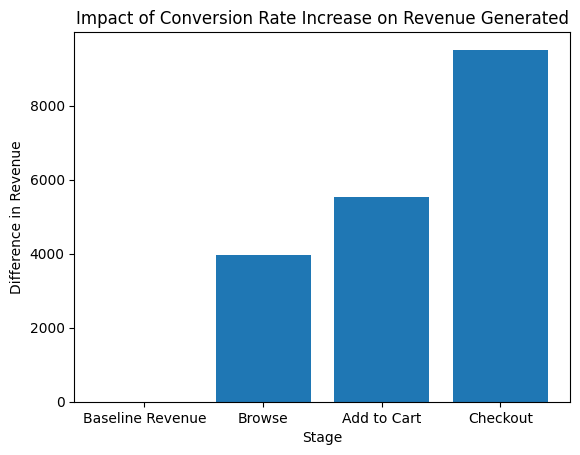

In [45]:
bar = plt.bar(row_headers, diff_rows)
plt.ylabel("Difference in Revenue")
plt.xlabel("Stage")
plt.title("Impact of Conversion Rate Increase on Revenue Generated")
plt.show()

# Increasing 1% of the Checkout Conversion Rate will have the biggest increase in revenue out of all the other events (~$9,500).

In [94]:
# Expected revenue = browse visitors * Browse Conversion Rate * Add to Card Conversion Rate * Checkout Conversion Rate * revenue per purchaser

# Find how many extra browsers are needed to get revenue increase as 1% increase in checkout conversion rate
extra_browsers = round(286838.55 / ((B_CR) / 100) / (ATC_CR / 100) / (C_CR / 100) / revenue_per_purchaser, 2) # ~344 extra browsers needed to get same amount of revenue

# Find what Browse Conversion Rate is needed to get revenue increase as 1% increase in checkout conversion rate
extra_B_CR = round(286838.55 / browse_visitors / (ATC_CR / 100) / (C_CR / 100) / revenue_per_purchaser, 2) # ~71.88% browser conversion rate needed to get same amount of revenue

# Find what Add to Cart Conversion Rate is needed to get revenue increase as 1% increase in checkout conversion rate
extra_ATC_CR = round(286838.55 / browse_visitors / (B_CR / 100) / (C_CR / 100) / revenue_per_purchaser, 2) # ~51.44% add to cart conversion rate needed to get same amount of revenue

print(extra_ATC_CR, ATC_CR)

browsing_data = [browse_visitors, extra_browsers - browse_visitors]
B_CR_data = [B_CR, (extra_B_CR * 100) - B_CR]
ATC_CR_data = [ATC_CR, (extra_ATC_CR * 100) -  ATC_CR]

rows = [browsing_data, B_CR_data, ATC_CR_data]
columns = ['Baseline', 'Extra Needed to Equal 1% Increase']
diff_rows = [browsing_data[1], B_CR_data[1], ATC_CR_data[1]]

catch_up_data = pd.DataFrame(data = rows, columns = columns)
row_headers = ['Browsers', 'Browse Conversion Rate', 'Add to Cart Conversion Rate']
catch_up_data.index = row_headers
catch_up_data

0.51 49.73


,Baseline,Extra Needed to Equal 1% Increase
Browsers,10000.00,344.23
Browse Conversion Rate,69.49,2.51
Add to Cart Conversion Rate,49.73,1.27


From the table above we need either 355 extra browsers coming to the site with the same conversion rates, an extra 2.51% on the browse conversion rate, or an extra 1.27% add to cart conversion rate to equal the same revenue generated from a 1% increase in checkout conversion rate.